# 03 · Placar das três configurações

Itens 05 e 06 da rubrica. As 36 perguntas rodam em `python -m src.avaliar` (resultados em `avaliacao/resultados_*.jsonl`). Este notebook lê os resultados salvos, recalcula o placar e lista os erros.

- **acerto**: respondeu com o fato do gabarito (perguntas da base), recusou (perguntas `nao_consta`) ou usou a ferramenta certa (perguntas dinâmicas).
- **alucinação**: respondeu com `consta=true` algo errado ou sem apoio.
- **recusa indevida**: recusou uma pergunta que a base responde. **Recusa segura**: recusou uma pergunta dinâmica (não inventou, mas não ajudou).

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import pandas as pd
pd.set_option('display.max_colwidth', 110)
from src import config
from src.avaliar import placar, classificar, carregar_perguntas
tab = placar()
tab

,configuracao,perguntas,acerto_total_%,alucinacao_%,acerto_base_%,recusa_correta_nao_consta_%,acerto_dinamicas_%,citacao_correta_%,json_valido_%,latencia_media_s
0,sem_contexto,36,13.9,61.1,8.0,42.9,0.0,0.0,100.0,1.15
1,rag,36,86.1,5.6,96.0,100.0,0.0,92.0,100.0,2.44
2,agente,36,83.3,11.1,80.0,100.0,75.0,87.5,100.0,2.91
3,agente_v2,36,91.7,8.3,88.0,100.0,100.0,84.0,100.0,2.23


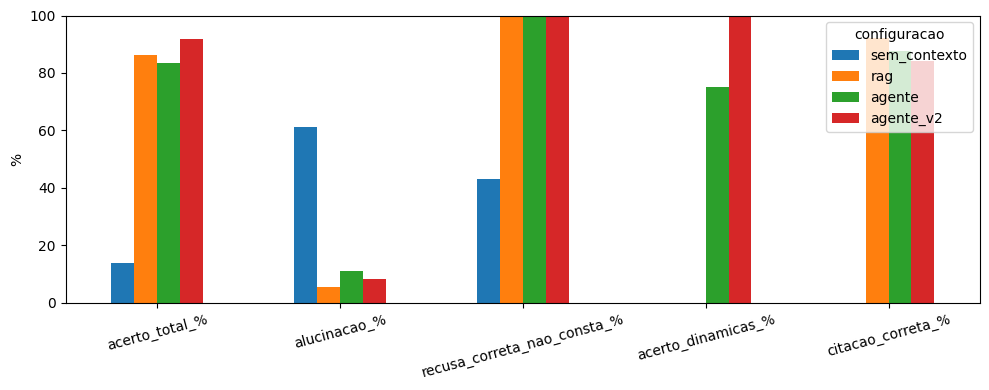

In [2]:
import matplotlib.pyplot as plt
cols = ['acerto_total_%', 'alucinacao_%', 'recusa_correta_nao_consta_%', 'acerto_dinamicas_%', 'citacao_correta_%']
ax = tab.set_index('configuracao')[cols].T.plot.bar(figsize=(10, 4), rot=15)
ax.set_ylabel('%'); ax.set_ylim(0, 100); plt.tight_layout(); plt.show()

### Resultado por pergunta

In [3]:
rs = pd.concat([pd.read_json(config.AVALIACAO / f'resultados_{c}.jsonl', lines=True) for c in tab.configuracao])
pp = {p['id']: p for p in carregar_perguntas()}
rs['classe'] = [classificar(pp[r['id']], r) for r in rs.to_dict('records')]
rs.pivot(index=['id', 'tipo'], columns='config', values='classe')[list(tab.configuracao)]

,config,sem_contexto,rag,agente,agente_v2
id,tipo,,,,
q01,base,alucinacao,acerto,acerto,acerto
q02,base,alucinacao,acerto,acerto,acerto
q03,base,recusa_indevida,acerto,alucinacao,alucinacao
q04,base,acerto,acerto,alucinacao,acerto
q05,base,alucinacao,acerto,acerto,acerto
q06,base,recusa_indevida,acerto,acerto,acerto
q07,base,alucinacao,acerto,acerto,acerto
q08,base,recusa_indevida,acerto,acerto,acerto
q09,base,alucinacao,acerto,acerto,acerto


### Erros (alucinações e recusas indevidas) para a análise dos 5 erros

In [4]:
erros = rs[rs.classe.isin(['alucinacao', 'recusa_indevida', 'erro_json'])]
erros[['config', 'id', 'pergunta', 'classe', 'resposta', 'fonte']].sort_values(['config', 'id'])

,config,id,pergunta,classe,resposta,fonte
2,agente,q03,Posso andar de bicicleta na calçada?,alucinacao,"Não, você não pode andar de bicicleta na calçada. Isso está proibido pela Resolução Contran nº 996/2023, a...",r996-art19
3,agente,q04,O que acontece se eu pedalar na calçada onde não é permitido?,alucinacao,"Se você pedalar na calçada onde não é permitida, isso pode ser considerado uma infração prevista no art. 1...",r996-art19
9,agente,q10,Até que velocidade o motor auxiliar de uma bicicleta elétrica pode ajudar?,alucinacao,O motor auxiliar de uma bicicleta elétrica pode ajudar até uma velocidade de até 6 km/h.,r996-art2-p1-p4
13,agente,q14,Qual velocidade devo respeitar com bicicleta elétrica dentro da ciclovia?,alucinacao,"De acordo com a Resolução Contran nº 996/2023, a velocidade máxima para bicicletas elétricas em ciclovias ...",r996-art7-art11
23,agente,q24,Quais ciclovias o CicloAlerta cobre hoje?,recusa_indevida,O CicloAlerta não forneceu informações sobre ciclovias hoje.,api:alertas
2,agente_v2,q03,Posso andar de bicicleta na calçada?,alucinacao,"Não, você não pode andar de bicicleta na calçada. Isso está proibido pela Resolução Contran nº 996/2023, a...",r996-art19
9,agente_v2,q10,Até que velocidade o motor auxiliar de uma bicicleta elétrica pode ajudar?,alucinacao,O motor auxiliar de uma bicicleta elétrica pode ajudar até uma velocidade de até 6 km/h.,r996-art2-p1-p4
21,agente_v2,q22,Quando o CicloAlerta emite um alerta crítico?,alucinacao,Há 7 alertas críticos e 9 alertas de atenção ativos agora. Os críticos estão em: Av. Brigadeiro Faria Lima...,api:alertas
9,rag,q10,Até que velocidade o motor auxiliar de uma bicicleta elétrica pode ajudar?,alucinacao,O motor auxiliar de uma bicicleta elétrica pode ajudar até uma velocidade de até 6 km/h.,r996-art2-p1-p4
34,rag,q35,Tem algum alerta crítico ativo nas ciclovias agora?,alucinacao,"Para verificar se há algum alerta crítico ativo, você precisaria consultar o mapa do CicloAlerta para ver ...",faq-alertas
